# Lab Exercises: Model Selection

1. Load data
1. Split train / test
1. CV for hyper-parameters
1. Re-train a model with the best hyper-parameters
1. Evaluate the model




## 1. Load data

Read data from `auto-mpg.csv`.

Source: [link](https://raw.githubusercontent.com/plotly/datasets/master/auto-mpg.csv).

In [1]:
# read CSV
import pandas as pd

# TODO: Read the data
df = pd.read_csv("auto-mpg.csv") # YOUR CODE HERE

# TODO: Remove missing value
df = df.dropna() # YOUR CODE HERE

df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model-year
0,18.0,8,307.0,130.0,3504,12.0,70
1,15.0,8,350.0,165.0,3693,11.5,70
2,18.0,8,318.0,150.0,3436,11.0,70
3,16.0,8,304.0,150.0,3433,12.0,70
4,17.0,8,302.0,140.0,3449,10.5,70


Column `mpg` is the **label** and the other columns are **feature**

In [2]:
# TODO: Get features and labels
X = df.drop('mpg', axis=1) # YOUR CODE HERE
y = df['mpg'] # YOUR CODE HERE
X.head()

,cylinders,displacement,horsepower,weight,acceleration,model-year
0,8,307.0,130.0,3504,12.0,70
1,8,350.0,165.0,3693,11.5,70
2,8,318.0,150.0,3436,11.0,70
3,8,304.0,150.0,3433,12.0,70
4,8,302.0,140.0,3449,10.5,70


## 2. Split Train / Test

`sklearn.model_selection.train_test_split` ([doc](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html))

In [3]:
from sklearn.model_selection import train_test_split

# TODO: Split data into train (75%) and test set (25%)
# Note: Please specify `random_state=0` for deterministic split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0) # YOUR CODE HERE

In [4]:
print('Train Size:', len(X_train))
print('Test Size:', len(X_test))

Train Size: 297
Test Size: 99


## 3. Cross Validation (TODO)

In this part, we are going to create a single pipeline for features and modeling. (This is often infeasible in real-world data, but that's a topic for another time.) Please check out the pipeline:

Hyper-parameter selection using `sklearn.model_selection.cross_validate` ([doc](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_validate.html)).

Key hyper-parameters for this pipeline:

- Scaler:
    - `StandardScaler`
    - `RobustScaler`
- `degree` of the polynomail features
- Regularization:
    - `LinearRegression` (no regularization)
    - `Ridge`: setting `alpha` (L2 regularization)
    - `Lasso`: setting `alpha` (L1 regularization)


Average Train MSE: 6.762121047233828
Average Validation MSE: 7.589586204746132


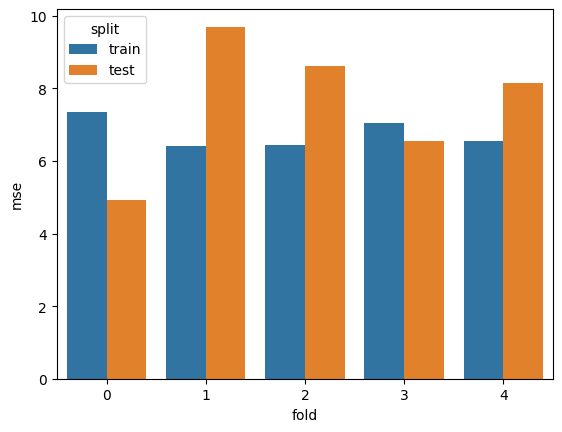

In [5]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_validate
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
import seaborn as sns

# TODO: change hyper-parameters
pipe = make_pipeline(
    # StandardScaler(),    # Mean-var scaler
    RobustScaler(),    # IQR Scaler
    PolynomialFeatures(degree=2),
    # LinearRegression(),  # No regularization
    # Ridge(alpha=0.05),  # L2 regularization
    Lasso(alpha=0.05),    # L1 regularization
)

k = 5
result = cross_validate(
    pipe,                       # model
    X_train, y_train,           # data
    scoring='neg_mean_squared_error',  # metric
    cv=k,                       # k-fold
    return_train_score=True)

result['train_score'] *= -1
result['test_score'] *= -1

print('Average Train MSE:', result['train_score'].mean())
print('Average Validation MSE:', result['test_score'].mean())

result_df = pd.DataFrame(
    {'mse': [*result['train_score'], *result['test_score']],
     'fold': [*range(5), *range(5)],
     'split': (['train'] * k) + (['test'] * k)})

__ = sns.barplot(x='fold', y='mse', hue='split', data=result_df)

Are we Overfitting or underfitting? Try to adjust hyper-parameter to find the balance.

## 4. Re-traing the model (TODO)

(need to find the best hyper-parameter first)

In [6]:
# TODO: Use "3. Cross Validation" to find best hyper-parameter
#       and build the best pipeline here using all training.

final_reg = make_pipeline(
    # StandardScaler(),    # Mean-var scaler
    RobustScaler(),    # IQR Scaler
    PolynomialFeatures(degree=2),
    # LinearRegression(),  # No regularization
    # Ridge(alpha=0.05),  # L2 regularization
    Lasso(alpha=0.05),    # L1 regularization
)
final_reg.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('robustscaler', ...), ('polynomialfeatures', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"with_centering with_centering: bool, default=TrueIf `True`, center the data before scaling.This will cause :meth:`transform` to raise an exception when attemptedon sparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_scaling with_scaling: bool, default=TrueIf `True`, scale the data to interquartile range.",True
,"quantile_range quantile_range: tuple (q_min, q_max), 0.0 < q_min < q_max < 100.0, default=(25.0, 75.0)Quantile range used to calculate `scale_`. By default this is equal tothe IQR, i.e., `q_min` is the first quantile and `q_max` is the thirdquantile... versionadded:: 0.18","(25.0, ...)"
,"copy copy: bool, default=TrueIf `False`, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"unit_variance unit_variance: bool, default=FalseIf `True`, scale data so that normally distributed features have avariance of 1. In general, if the difference between the x-values of`q_max` and `q_min` for a standard normal distribution is greaterthan 1, the dataset will be scaled down. If less than 1, the datasetwill be scaled up... versionadded:: 0.24",False
,"degree degree: int or tuple (min_degree, max_degree), default=2If a single int is given, it specifies the maximal degree of thepolynomial features. If a tuple `(min_degree, max_degree)` is passed,then `min_degree` is the minimum and `max_degree` is the maximumpolynomial degree of the generated features. Note that `min_degree=0`and `min_degree=1` are equivalent as outputting the degree zero term isdetermined by `include_bias`.",2
,"interaction_only interaction_only: bool, default=FalseIf `True`, only interaction features are produced: features that areproducts of at most `degree` *distinct* input features, i.e. terms withpower of 2 or higher of the same input feature are excluded:- included: `x[0]`, `x[1]`, `x[0] * x[1]`, etc.- excluded: `x[0] ** 2`, `x[0] ** 2 * x[1]`, etc.",False


## 5. Evaluation (TODO)

Use `sklearn.metrics.mean_squared_error` to compute MSE

In [7]:
from sklearn.metrics import mean_squared_error

pred_train = final_reg.predict(X_train)
mse_train = mean_squared_error(y_train, pred_train)

# TODO: Get "test" performance (MSE)
pred_test = final_reg.predict(X_test)
mse_test = mean_squared_error(y_test, pred_test)

print('Performance Report:')
print('- Train MSE:', mse_train)
print('- Test MSE:', mse_test)

Performance Report:
- Train MSE: 6.848759327887201
- Test MSE: 9.773059974164596
